# Online Shoppers Intention: Exploratory Data Analysis

Load the workspace CSV, inspect its rows and data quality, prepare categorical fields, summarize measured numeric features, and plot their distributions.

In [1]:
from pathlib import Path

import pandas as pd

data_path = Path("datasets") / "online_shoppers_intention.csv"
df = pd.read_csv(data_path)

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

print("\nColumn data types:")
display(df.dtypes.rename("dtype").to_frame())

Dataset shape: 12,330 rows × 18 columns


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False



Column data types:


,dtype
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


## Data quality and preparation

Keep the original data unchanged. Represent month and coded/boolean fields as categories; do not impute or drop rows unless missing values are found. Operating-system, browser, region, and traffic-type numbers are category codes, not measurements.

In [2]:
df_prepared = df.copy()

month_order = ["Jan", "Feb", "Mar", "Apr", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
df_prepared["Month"] = pd.Categorical(df_prepared["Month"], categories=month_order, ordered=True)
categorical_columns = [
    "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType", "Weekend", "Revenue"
]
df_prepared[categorical_columns] = df_prepared[categorical_columns].astype("category")

missing_summary = pd.DataFrame({
    "missing_values": df_prepared.isna().sum(),
    "missing_percent": (df_prepared.isna().mean() * 100).round(2),
})
print(f"Total missing values: {int(df_prepared.isna().sum().sum()):,}")
display(missing_summary)

print(f"Rows retained after preparation: {len(df_prepared):,} of {len(df):,}")
display(df_prepared.dtypes.rename("prepared_dtype").to_frame())

Total missing values: 0


,missing_values,missing_percent
Administrative,0,0.0
Administrative_Duration,0,0.0
Informational,0,0.0
Informational_Duration,0,0.0
ProductRelated,0,0.0
ProductRelated_Duration,0,0.0
BounceRates,0,0.0
ExitRates,0,0.0
PageValues,0,0.0
SpecialDay,0,0.0


Rows retained after preparation: 12,330 of 12,330


,prepared_dtype
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


## Mean, median, and standard deviation

Statistics below cover page counts, durations, rates, and page values. Categorical ID codes are excluded because their arithmetic mean or standard deviation is not substantively meaningful.

In [3]:
measurement_columns = [
    "Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues", "SpecialDay",
]
statistics = pd.DataFrame({
    "mean": df_prepared[measurement_columns].mean(),
    "median": df_prepared[measurement_columns].median(),
    "std_deviation": df_prepared[measurement_columns].std(),
}).round(3)
display(statistics)

,mean,median,std_deviation
Administrative,2.315,1.000,3.322
Administrative_Duration,80.819,7.500,176.779
Informational,0.504,0.000,1.270
Informational_Duration,34.472,0.000,140.749
ProductRelated,31.731,18.000,44.476
ProductRelated_Duration,1194.746,598.937,1913.669
BounceRates,0.022,0.003,0.048
ExitRates,0.043,0.025,0.049
PageValues,5.889,0.000,18.568
SpecialDay,0.061,0.000,0.199


## Feature distributions

Histograms show measured numeric features. Bar charts show categorical and boolean feature counts.

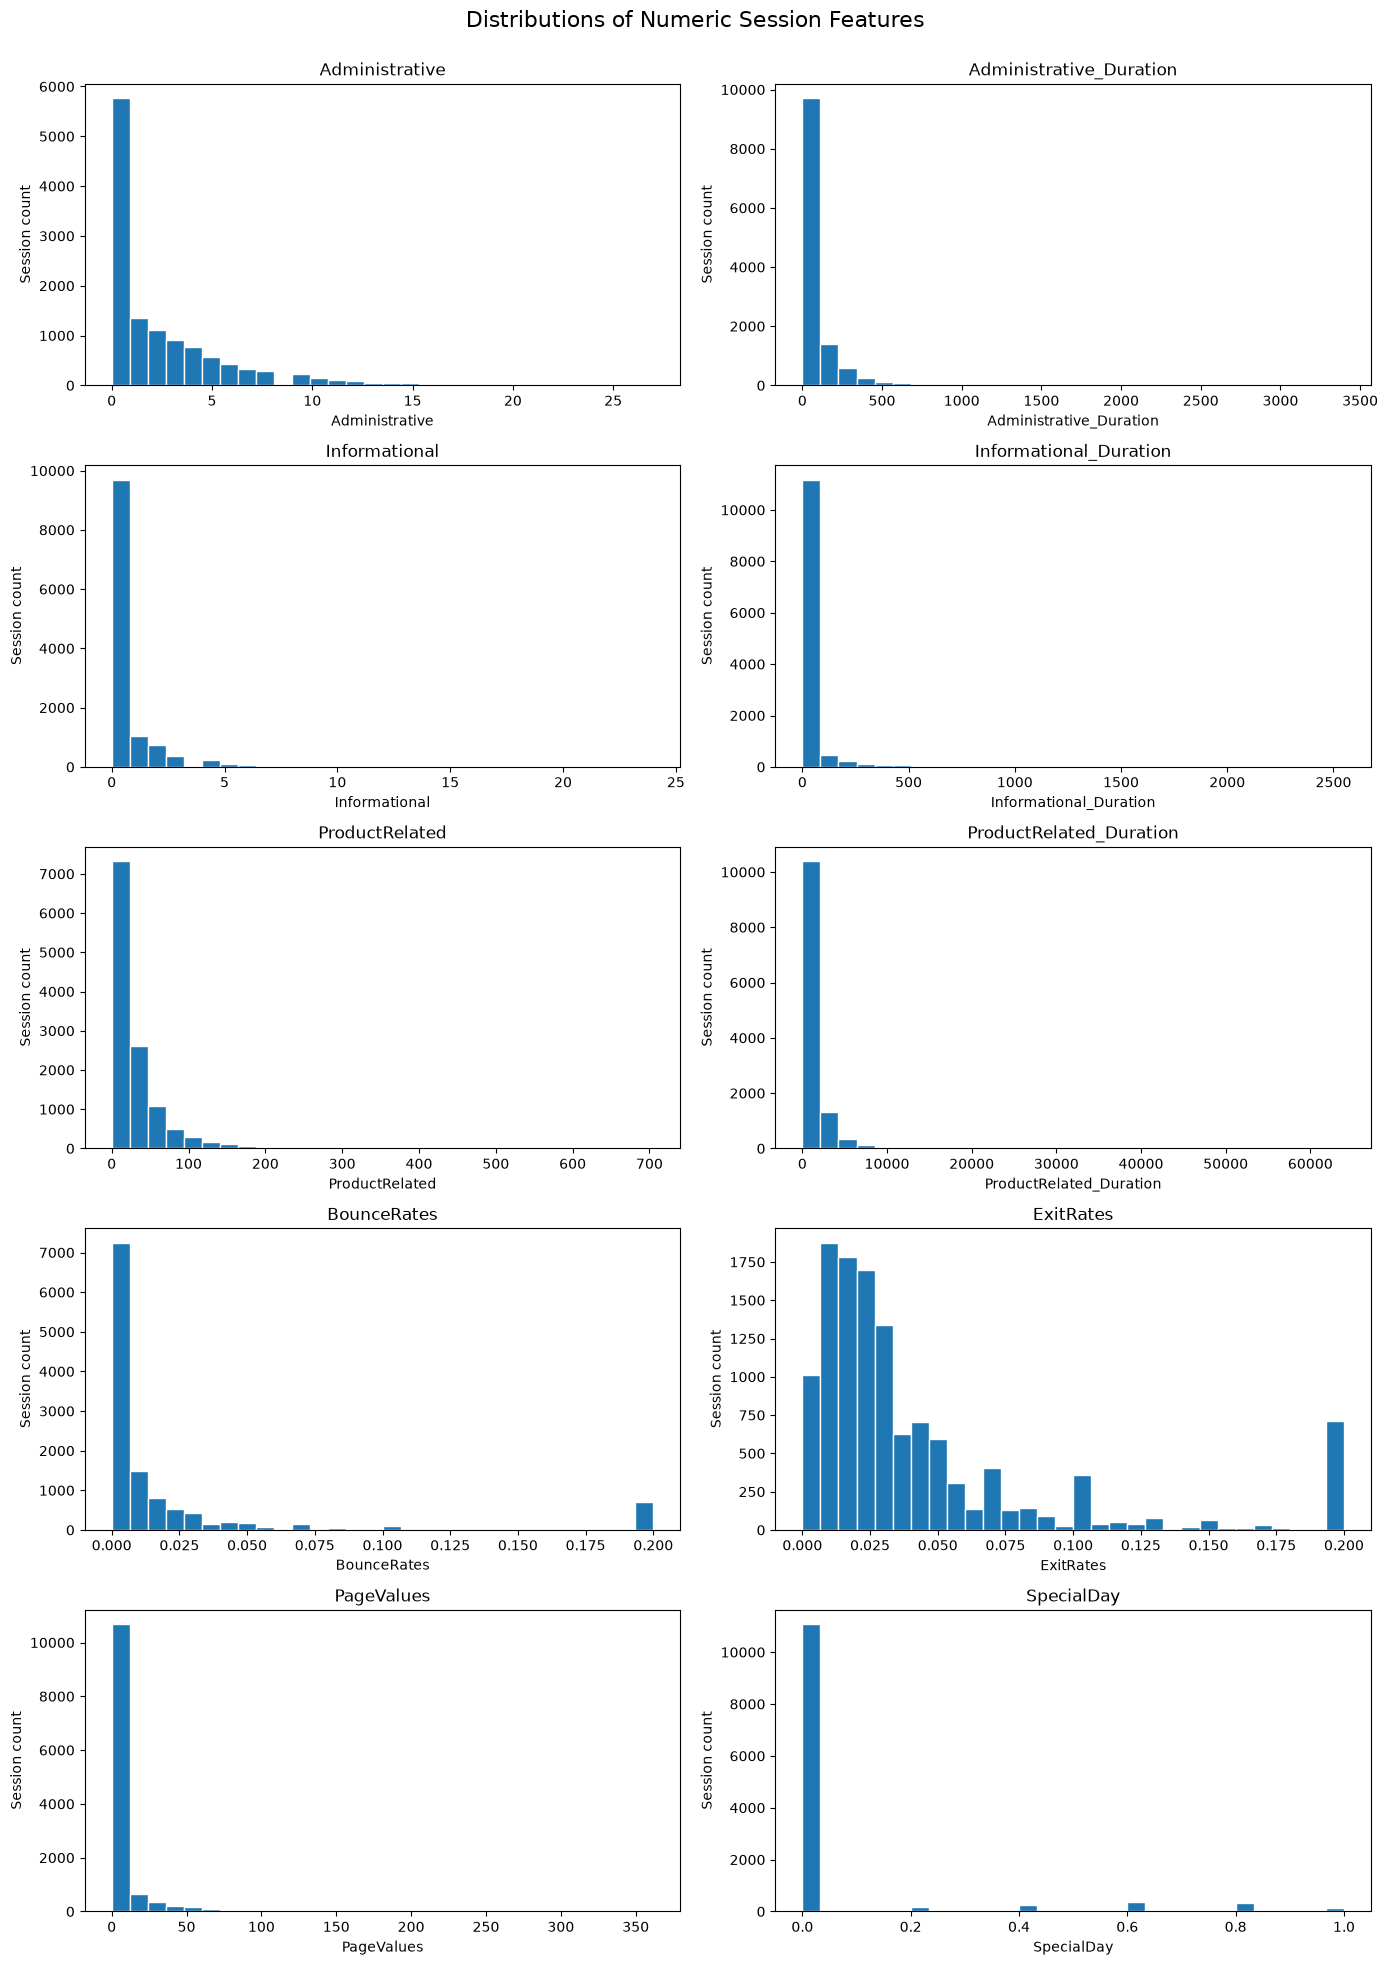

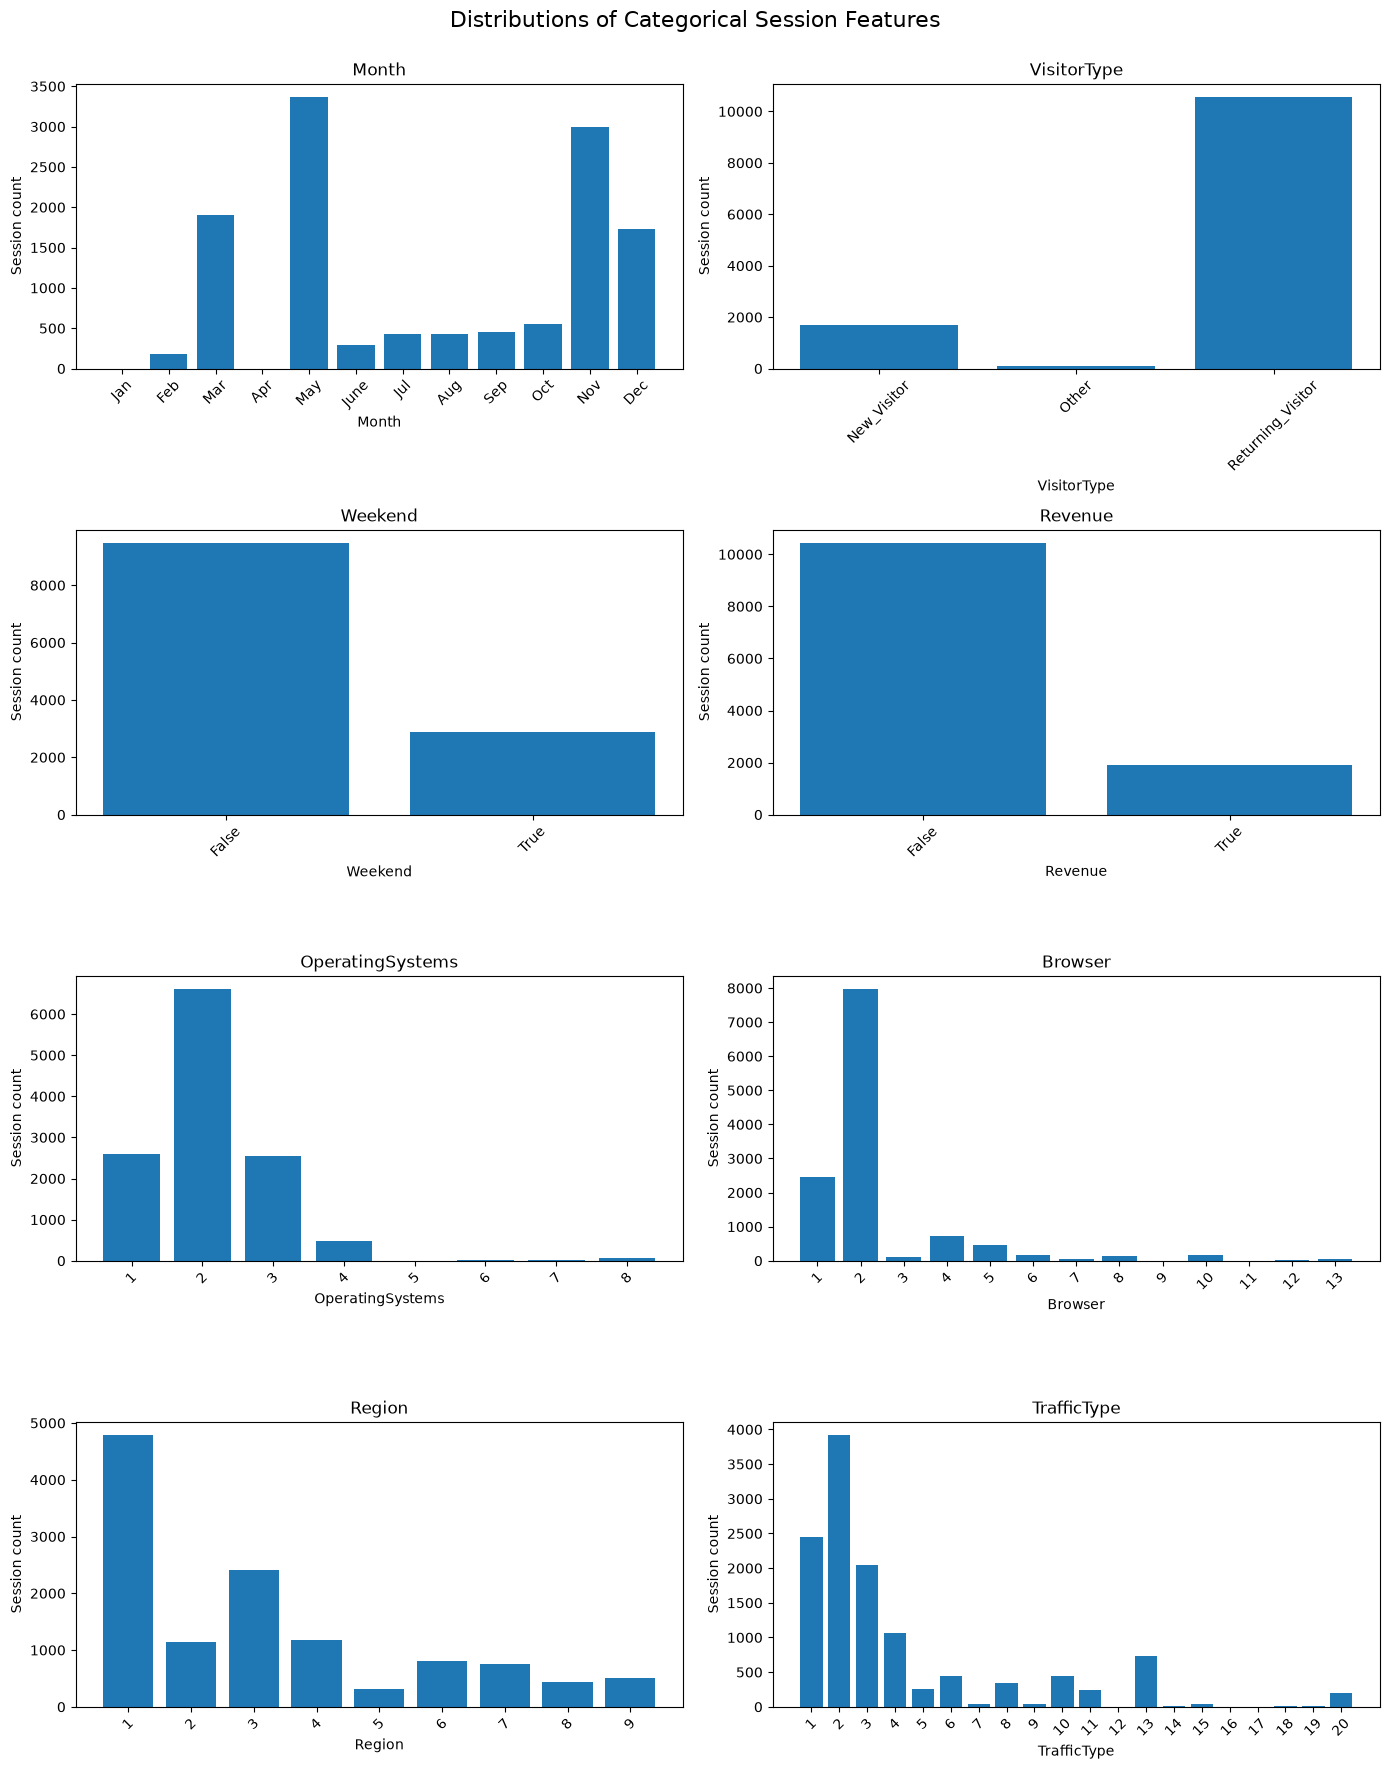

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(5, 2, figsize=(14, 20))
for column, ax in zip(measurement_columns, axes.flat):
    ax.hist(df_prepared[column], bins=30, edgecolor="white")
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Session count")
fig.suptitle("Distributions of Numeric Session Features", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

distribution_columns = ["Month", "VisitorType", "Weekend", "Revenue", "OperatingSystems", "Browser", "Region", "TrafficType"]
fig, axes = plt.subplots(4, 2, figsize=(14, 18))
for column, ax in zip(distribution_columns, axes.flat):
    counts = df_prepared[column].value_counts(sort=False, dropna=False)
    ax.bar(counts.index.astype(str), counts.values)
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Session count")
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Distributions of Categorical Session Features", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()